# 2. Análisis Exploratorio del Train Set

Este proyecto usó datos del [**"Online Shoppers Purchasing Intention Dataset"**](https://doi.org/10.24432/C5F88Q) creado por C. Sakar y Yomi Kastro (2018), alojado en el "UCI Machine Learning Repository". El dataset original tiene una licencia [**CC BY 4.0**](https://creativecommons.org/licenses/by/4.0/legalcode). Sobre los registros originales se aplicaron transformaciones de limpieza y preprocesamiento, particionado (*train/test*) y generación de variables derivadas. El código fuente de este proyecto se distribuye bajo la **Licencia MIT** (ver archivo `LICENSE`).

## 2.0. Importación de librerías y datos

In [1]:
#Importamos librerías
import pandas as pd
import numpy as np
import joblib
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from scipy.stats.contingency import association
from scipy.stats import kruskal

In [2]:
#Importamos los sets
df_shoppers_sets = joblib.load("../data/interim/df_shoppers_split.joblib")

In [3]:
#Guardamos el train_set en una variable
train_set = df_shoppers_sets["train_set"]

# 2.1. Descripción univariante

Ahora vamos a ver una descripción de estadísticos de las distintas variables del train set:

a) Variables numéricas:

In [4]:
train_set.describe()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType,Weekend,Revenue,ProductRelated_Ratio,ProductRelated_Duration_Ratio,Duration_Per_Product_Page
count,9864.000000,9864.000000,9864.000000,9864.000000,9864.000000,9864.000000,9864.000000,9864.000000,9864.000000,9864.000000,9864.000000,9864.000000,9864.000000,9864.000000,9864.000000,9864.000000,9864.000000,9864.000000,9864.000000
mean,2.317620,81.241059,0.504663,34.590252,31.452758,1186.546010,0.022396,0.043313,5.944562,0.062693,2.127534,2.366788,3.152778,4.071168,0.231752,0.154704,0.904857,0.841728,37.620301
std,3.319144,179.610421,1.275169,141.428972,43.615440,1909.252291,0.048809,0.048901,18.562169,0.201271,0.918098,1.732810,2.395939,4.015231,0.421973,0.361641,0.141012,0.269590,44.268012
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,182.566071,0.000000,0.014286,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000,0.000000,0.000000,0.858937,0.821748,17.521507
50%,1.000000,8.000000,0.000000,0.000000,18.000000,600.536667,0.003110,0.025195,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.962963,0.966235,28.893959
75%,4.000000,93.000000,0.000000,0.000000,38.000000,1474.508333,0.017081,0.050000,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000,0.000000,0.000000,1.000000,1.000000,45.202885
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000,1.000000,1.000000,1.000000,1.000000,1411.000000


b) Variables no numéricas:

In [5]:
train_set.describe(exclude=['number'])

,Month,VisitorType
count,9864,9864
unique,10,3
top,May,Returning_Visitor
freq,2703,8443


c) Describamos ciertas variables numéricas como categóricas:

In [6]:
#Tratemos ciertas numericas como categóricas
cols_num_cat=['OperatingSystems', 'Browser', 'Region', 'TrafficType', 'Weekend', 'Revenue']
train_set[cols_num_cat].astype('category').describe()

,OperatingSystems,Browser,Region,TrafficType,Weekend,Revenue
count,9864,9864,9864,9864,9864,9864
unique,8,13,9,20,2,2
top,2,2,1,2,0,0
freq,5275,6361,3782,3135,7578,8338


## 2.2. Análisis Univariante

a) Variables categóricas:

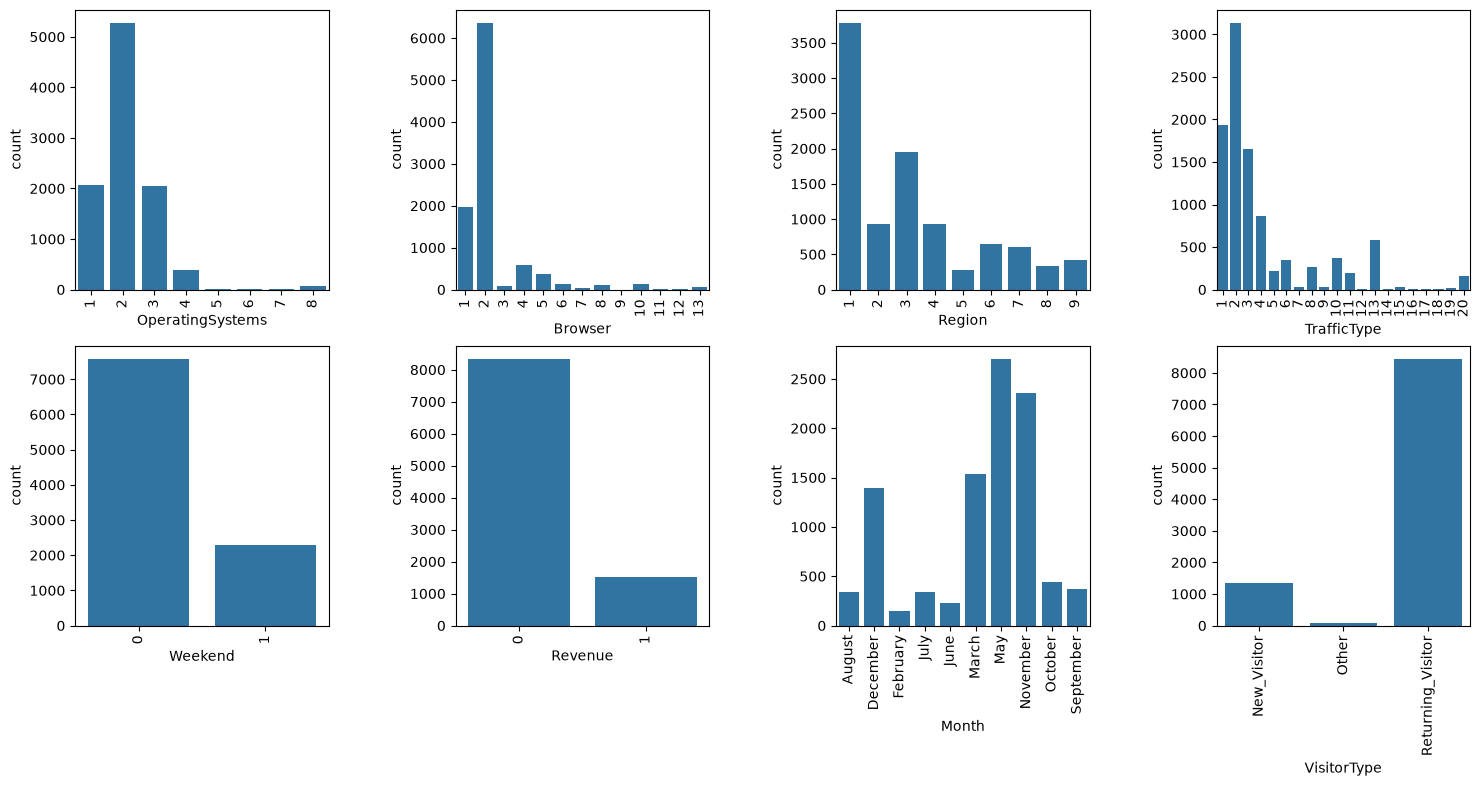

In [7]:
#0. Definimos todas las categoricas
cols_cat = cols_num_cat + ["Month", "VisitorType"]
#1. Empieza el plot
fig_univ_cat, axes = plt.subplots(2, 4, figsize=(18,8))
axes = axes.flatten()

#2. Generamos boxplots = a plot_boxplot_custom para cada columna
for i, column in enumerate(cols_cat):
    #Generamos countplot
    sns.countplot(data=train_set, x=train_set[column].astype('category'), ax=axes[i])
#3. Para añadir espacio entre plots
plt.subplots_adjust(wspace=0.5)
for ax in fig_univ_cat.axes: ax.tick_params(axis='x', labelrotation=90)

Vemos varias cosas:

- Las distintas categorías posibles para cada variable han sido representadas al compararlo con los valores únicos posibles del dataset completo.
* Con respecto a:
    - `Month` vemos que hay meses que acumulan más sesiones que el resto, en especial May y November, seguidos por March y December.
    - `VisitorType` vemos que la mayoría son Returning Visitors.
    - `Weekend` vemos que entre semana presenta más sesiones, aunque es normal aqui se consideran 5 días con respecto a los 2 días del fin de semana.
    - `Revenue` vemos que la variable target sigue estando desbalanceada, siendo las sesiones sin compra el caso mayoritario.
    - `OperatingSystems` vemos que el mayoritario es el 2, seguido por 1 y 3, aunque no aporta mucho a nivel de comportamientos del usuario, ni son interpretables ya que desconocemos la codificación.
    - `Browser` vemos que el mayoritario es el 2, seguido por 1, aunque no aporta mucho a nivel de comportamientos del ususario, ni son interpretables ya que desconocemos la codificación.
    - `Region` vemos que la 1 es la mayoritaria, seguida por la 3, aunque no son interpretables ya que desconocemos la codificación.
    - `TrafficType` vemos que el 2 es el mayoritario, seguido por el 1 y 3, aunque no son interpretables ya que desconocemos la codificación. 

b) Variables numéricas (boxplots):

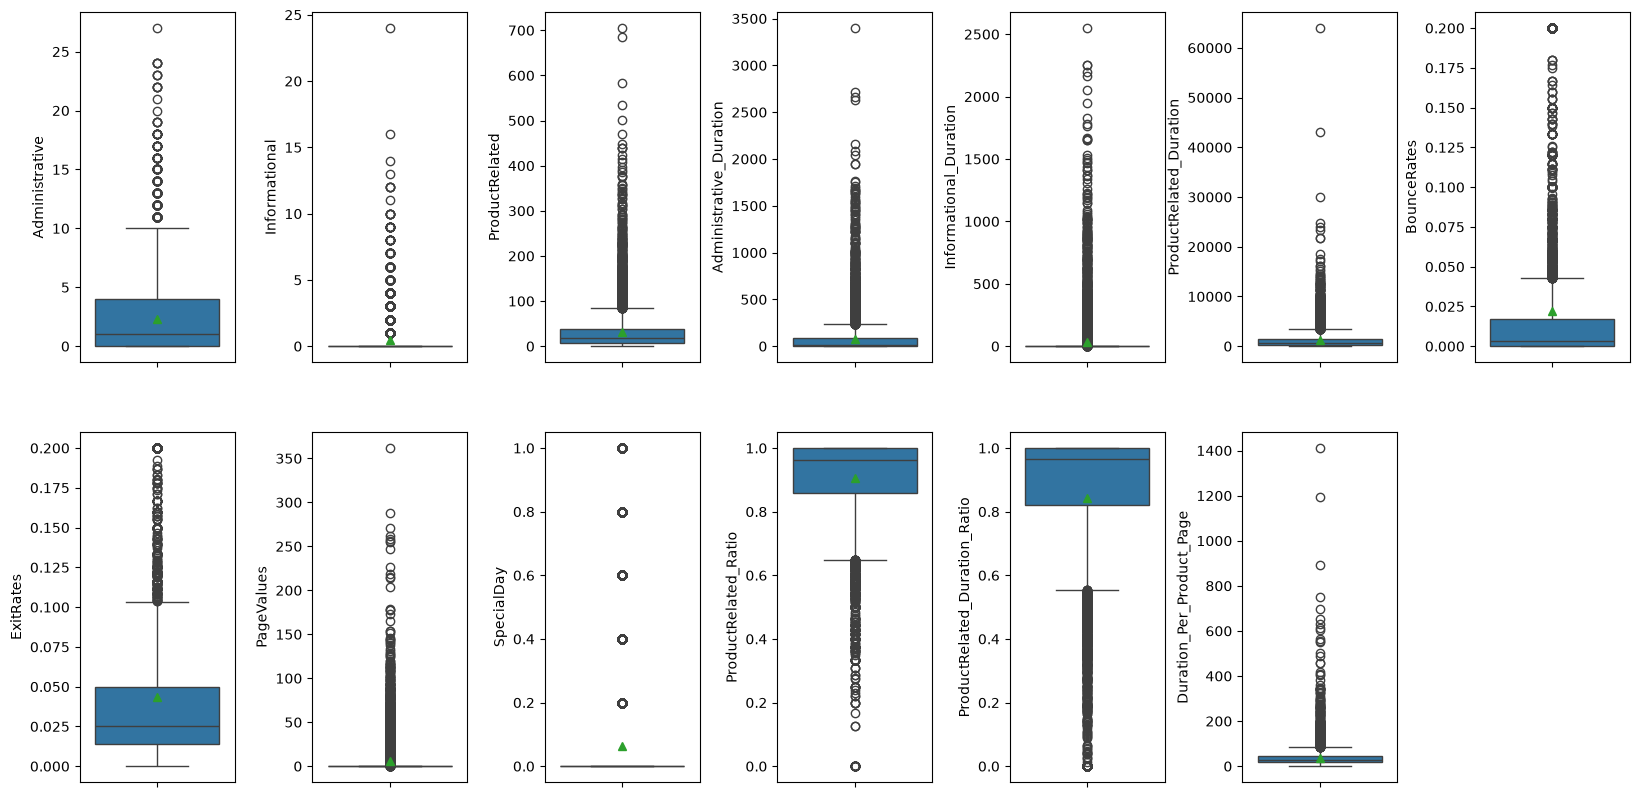

In [8]:
#0. Definimos todas las categoricas
cols_num = ['Administrative', 'Informational', 'ProductRelated',
            'Administrative_Duration','Informational_Duration', 'ProductRelated_Duration',
            'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay',
            'ProductRelated_Ratio','ProductRelated_Duration_Ratio', 'Duration_Per_Product_Page']
#1. Empieza el plot
fig_univ_num_boxplot, axes = plt.subplots(2, 7, figsize=(20,10))
axes = axes.flatten()

#2. Generamos boxplots = a plot_boxplot_custom para cada columna
for i, column in enumerate(cols_num):
    #Generamos countplot
    sns.boxplot(data=train_set, y=train_set[column], ax=axes[i], showmeans=True)
#3. Para añadir espacio entre plots
plt.subplots_adjust(wspace=0.5)
# 4. Ocultar los subgráficos vacíos restantes
for j in range(len(cols_num), len(axes)):
    axes[j].set_visible(False)

Vemos algunas cosas que podemos confirmar en los describe previos:
- Con respecto a las 3 categorías `ProductRelated` muestra medias y medianas mayores que las otras dos categorías tanto en número de página como en duración, con `Administrative` presentando valores mayores que `Informational`, lo que entra dentro de lo esperado.
* Con respecto a las variables de Google Analytics, `BounceRates` y `ExitRates` tienen valores máximos de 0.2 lo que podría indicar un tope artificial.  Por lo que se ha podido investigar es efectivamente un tope (cap) aplicado en el preprocesamiento o anonimización de los datos, y no una limitación nativa de Google Analytics. Por otro lado, `PageValues` suele presentar valores muy bajos.
- `SpecialDay` también suele presentar valores bajos.
* Con respecto a las variables derivadas, vemos en `ProductRelated_Ratio` y `ProductRelated_Duration_Ration` que las páginas relacionadas con Productos suelen representar la mayor parte de las páginas visitadas y la duración de las sesiones. Por otro lado, `Duration_Per_Product_Page` nos ayuda a ver la duración por páginas de productos que tienen una duración media de 37.62.

c) Variables numéricas (histogramas):

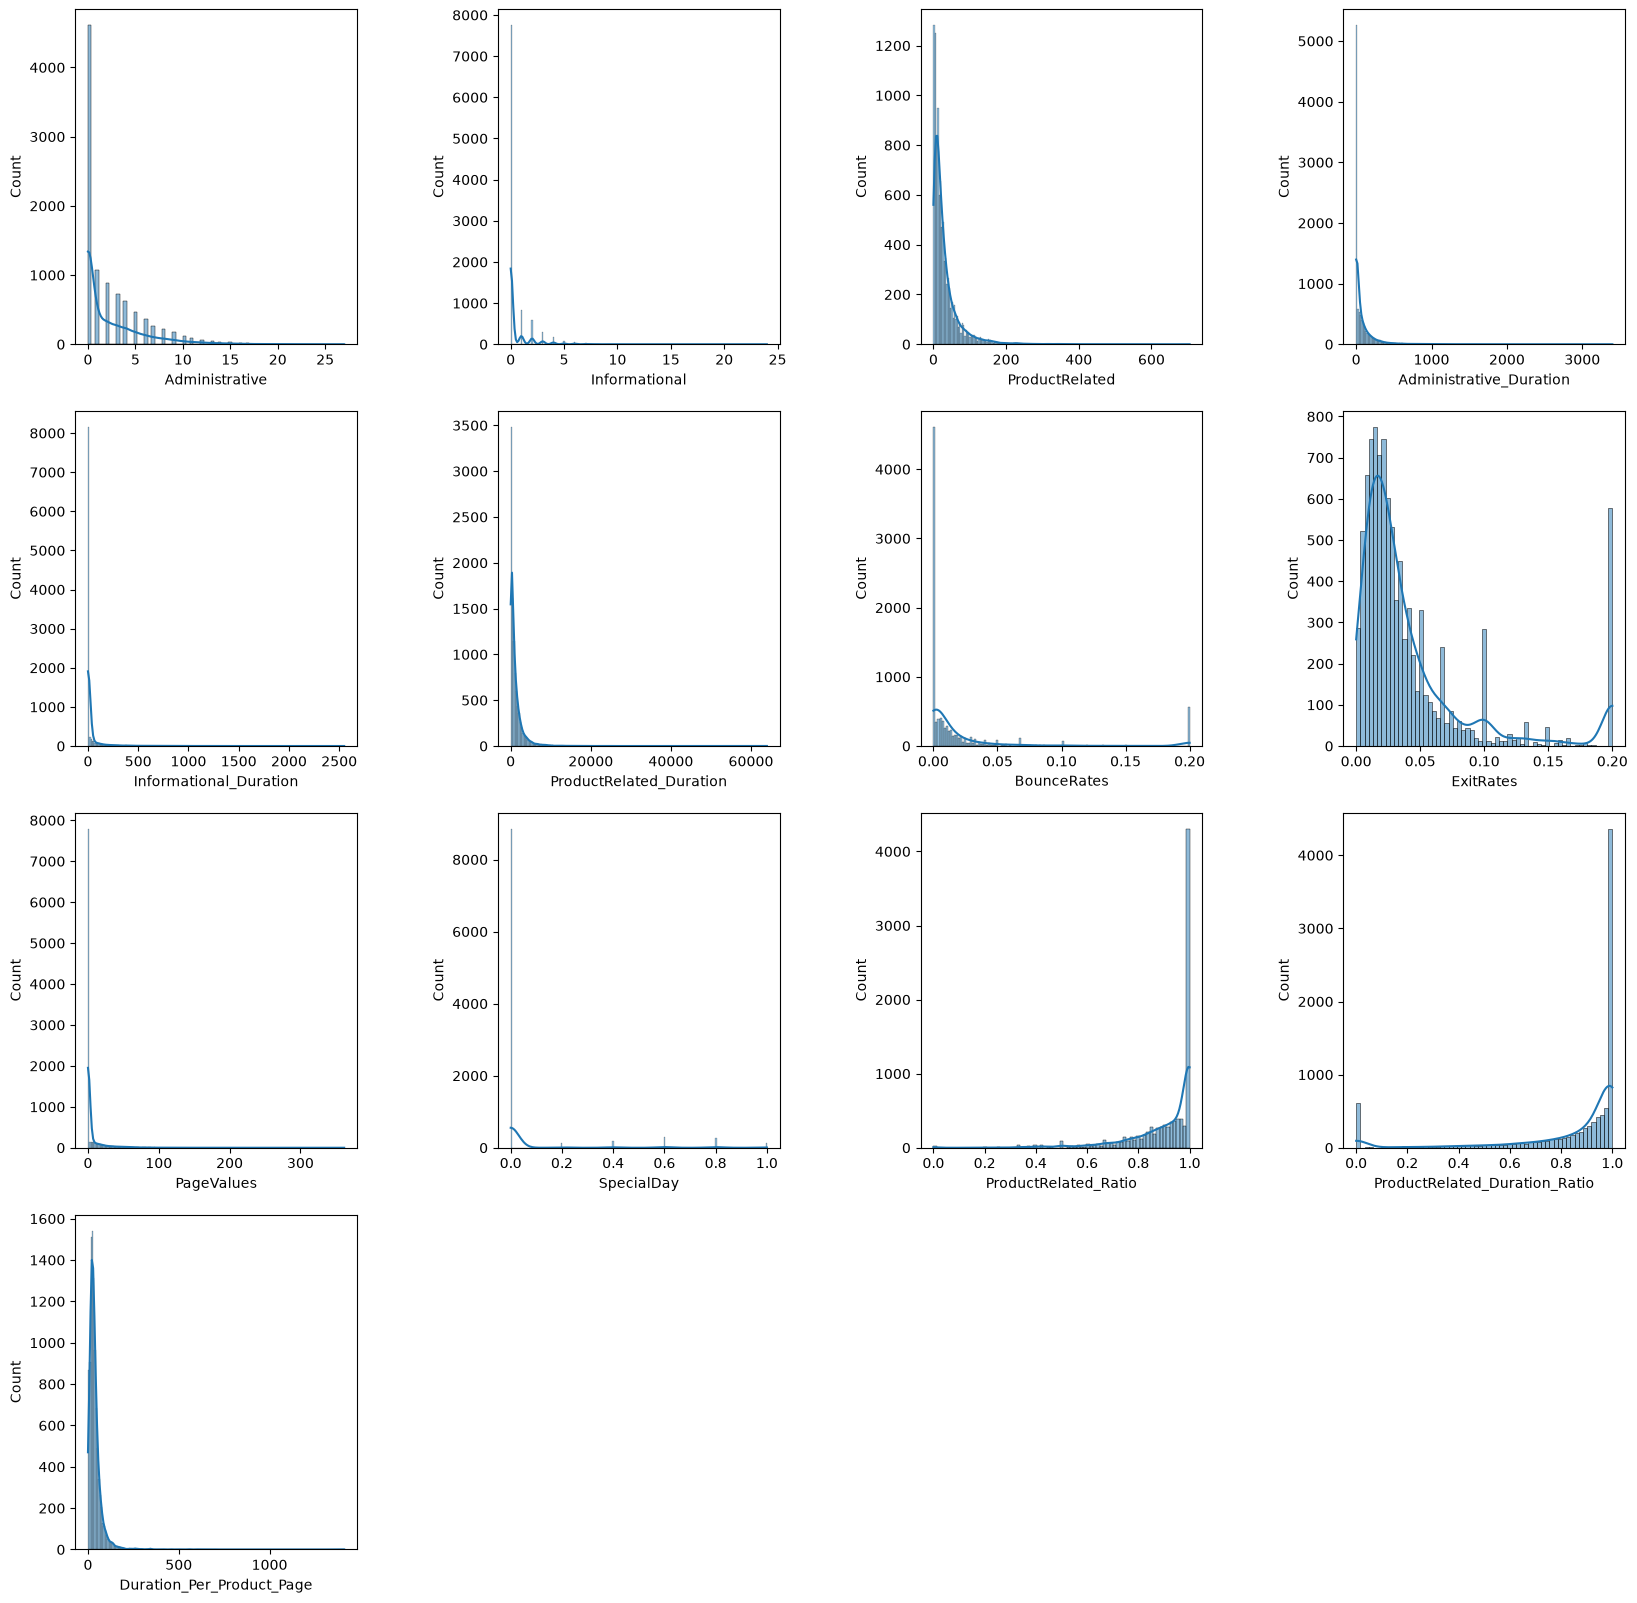

In [9]:
#1. Empieza el plot
fig_univ_num_hist, axes = plt.subplots(4, 4, figsize=(20,20))
axes = axes.flatten()

#2. Generamos boxplots = a plot_boxplot_custom para cada columna
for i, column in enumerate(cols_num):
    #Generamos countplot
    sns.histplot(train_set[column], kde=True, ax=axes[i], bins= "auto")
#3. Para añadir espacio entre plots
plt.subplots_adjust(wspace=0.5)
# 4. Ocultar los subgráficos vacíos restantes
for j in range(len(cols_num), len(axes)):
    axes[j].set_visible(False)

Vemos varias cosas:

- Encontramos ciertas variables (`Administrative`, `Informational`, `ProductRelated`, `Administrative_Duration`, `Informational_Duration`, `ProductRelated_Duration`, `PageValues` y `Duration_Per_Product_Page`) relacionadas con conteos, duraciones y valores monetarios que presentan grandes picos a la izquierda cerca de cero y colas a la derecha, para las cuales aplicar una **transformación logarítmica como np.log1p podría ser interesante** para simetrizar y comprimir la escala.

* También tenemos los ratios de proporción de producto (`ProductRelated_Ratio` y `ProductRelated_Duration_Ratio`) que muestran grandes picos a la derecha cercanos a 1 y colas a la izquierda. Por otro lado, `SpecialDay` tiene un gran pico en torno a cero y escalones discretos hasta 1. Además, `BounceRates` y `ExitRates` presentan una bimodalidad con un pico principal cercano a cero y un segundo pico menor en torno a 0.2. En todos estos casos, no conviene aplicar una logarítmica, pues ya están dentro de una escala acotada 0-1 que ya es de por sí comprimida y que no corregiría ni la asimetria ni la bimodalidad.

- Finalmente, a todas estas variables convendría aplicar el mismo escalado **StandardScaler** para centrar sus distribuciones, y garantizar que sean comparables entre sí de cara a modelos sensibles a la escala.

d) Comprobación de las transformaciones sugeridas:

In [10]:
#Preparamos un pequeño pipeline de preprocesamiento numérico

# 1. Definir los grupos de columnas numéricas según tu análisis
cols_log_scaler = [
    'Administrative', 'Informational', 'ProductRelated',
    'Administrative_Duration', 'Informational_Duration', 'ProductRelated_Duration',
    'PageValues', 'Duration_Per_Product_Page'
]

cols_scaler_only = [
    'ProductRelated_Ratio', 'ProductRelated_Duration_Ratio',
    'SpecialDay', 'BounceRates', 'ExitRates'
]

# 2. Crear el sub-pipeline para las cols_log_scaler
pipeline_log_scaler = Pipeline(steps=[
    ('log1p', FunctionTransformer(func=np.log1p, inverse_func=np.expm1, feature_names_out="one-to-one")),
    ('scaler', StandardScaler())
])

# 3. Unificar ambas transformaciones en un ColumnTransformer
preprocesador_numerico = ColumnTransformer(
    transformers=[
        ('log_scaler', pipeline_log_scaler, cols_log_scaler),
        ('scaler_only', StandardScaler(), cols_scaler_only)
    ],
    remainder='passthrough', # Deja intactas el resto de columnas (categóricas/binarias)
    verbose_feature_names_out=False # Mantiene los nombres originales de las columnas
).set_output(transform='pandas') # Devuelve un DataFrame de pandas en lugar de un array numpy

# 4. Ajustar SOLO con train y transformar tanto train como test
train_set_nums_prep = clone(preprocesador_numerico).fit_transform(train_set)

In [11]:
#Guardamos el resultado en CSV
train_set_nums_prep.to_csv("../data/interim/train_set_nums_prep.csv", sep=",")

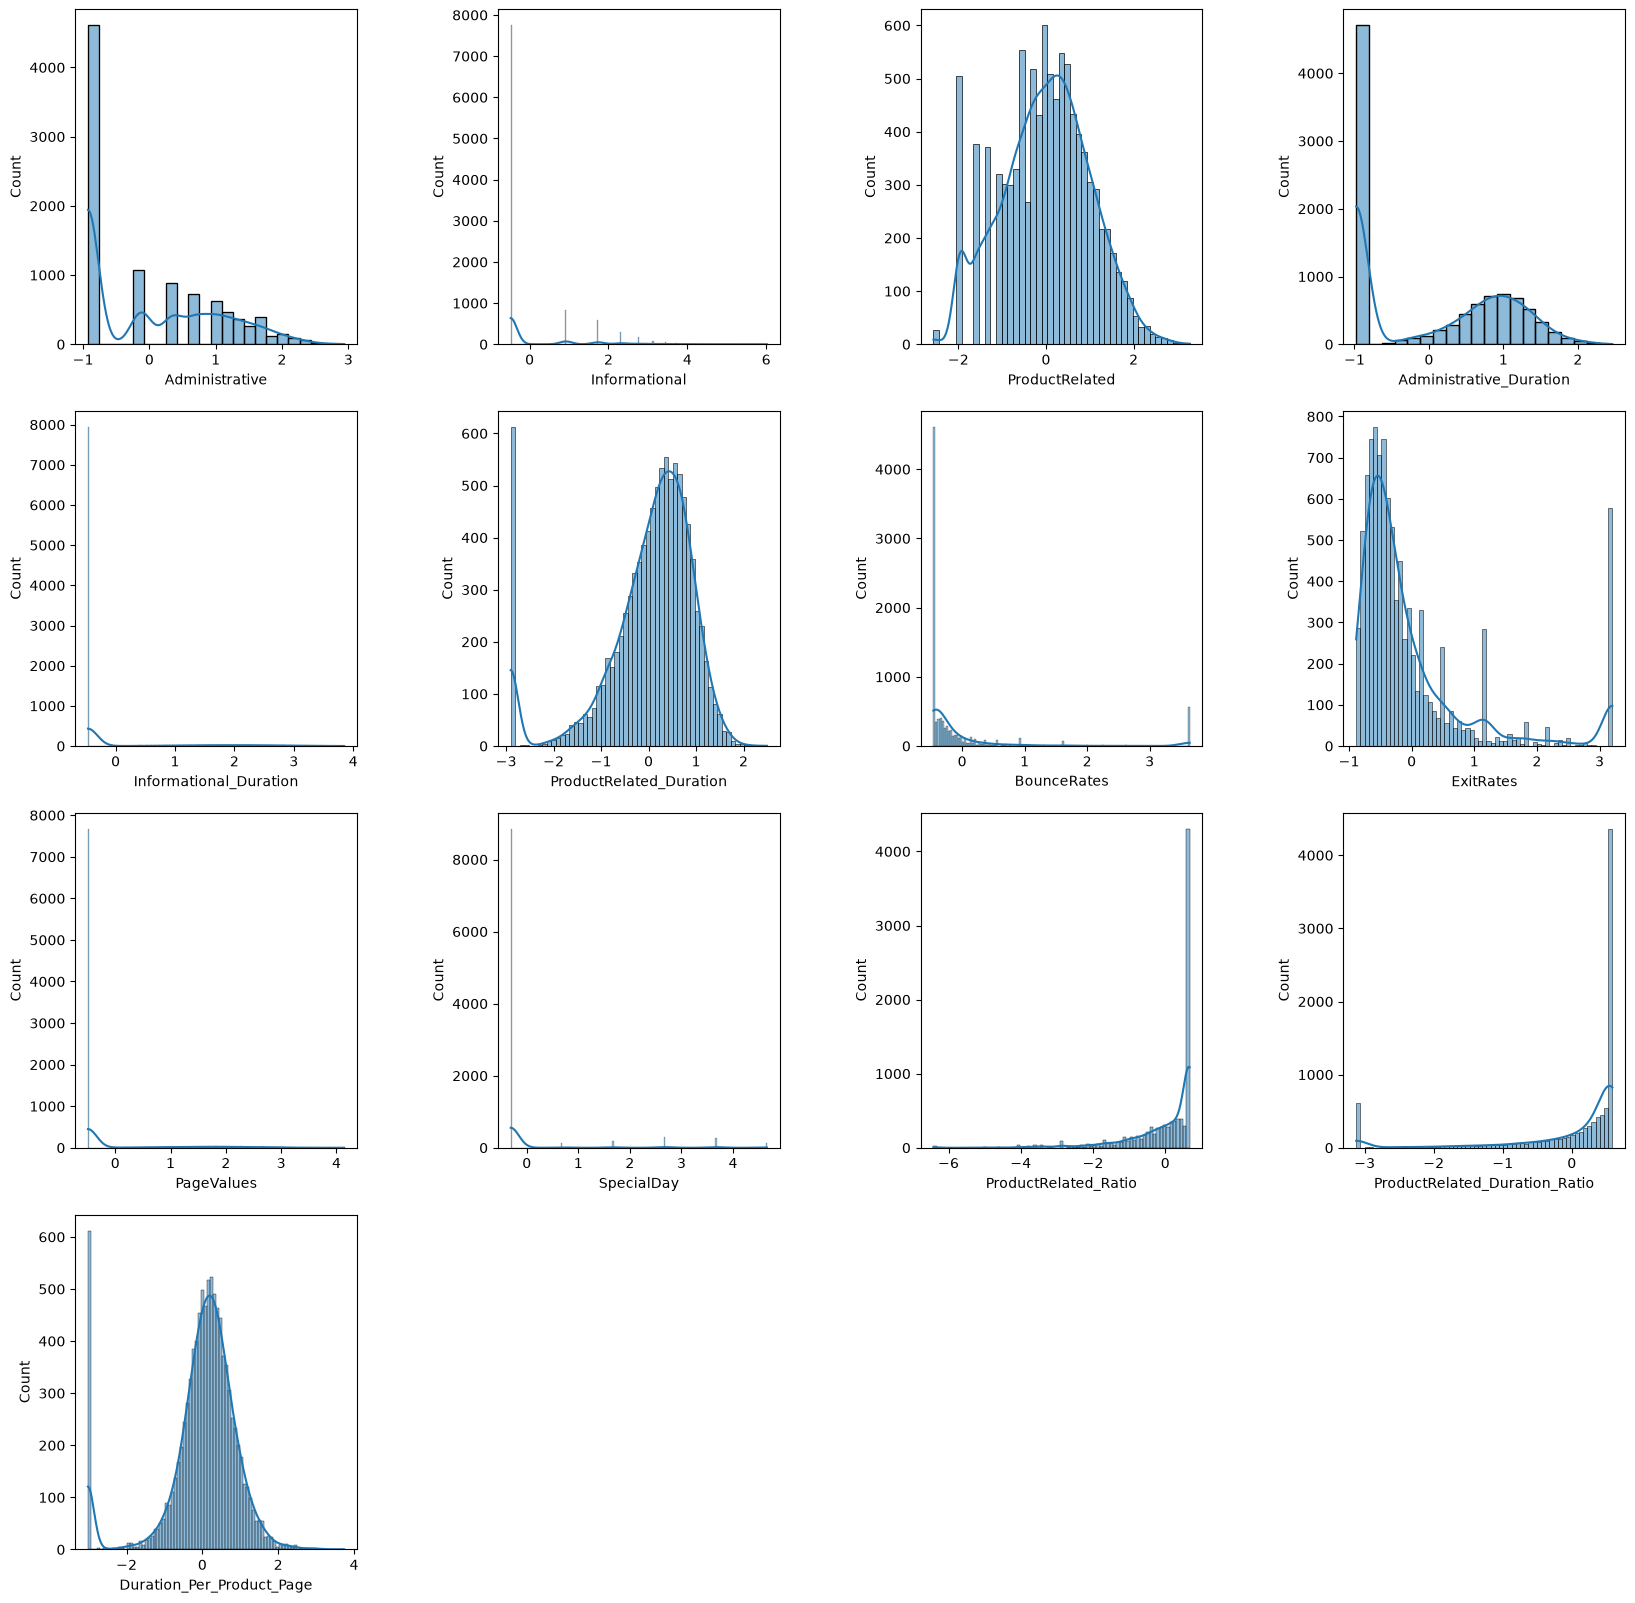

In [12]:
#1. Empieza el plot
fig_univ_numprep_hist, axes = plt.subplots(4, 4, figsize=(20,20))
axes = axes.flatten()

#2. Generamos boxplots = a plot_boxplot_custom para cada columna
for i, column in enumerate(cols_num):
    #Generamos countplot
    sns.histplot(train_set_nums_prep[column], kde=True, ax=axes[i], bins= "auto")
#3. Para añadir espacio entre plots
plt.subplots_adjust(wspace=0.5)
# 4. Ocultar los subgráficos vacíos restantes
for j in range(len(cols_num), len(axes)):
    axes[j].set_visible(False)

Vemos ciertas cosas:

- Para las variables que hemos aplicado log1p y scaler, vemos diferentes comportamientos. Algunas la distribución ahora se asemeja más a una campana (`ProductRelated`), otras que presentan una campana y un pico a la izquierda representando una bimodalidad (`Administrative_Duration`, `ProductRelated_Duration` y `Duration_Per_Product_Page`), y otras que su distribución no cambia demasiado por sus altas proporciones de ceros (`Administrative`, `Informational`, `Informational_Duration`, y `PageValues`).

* Para el resto de variables que hemos aplicado solo el scaler, vemos que presentan distribuciones iguales pero con un cambio de escala.

- Al aplicar el scaler, acabamos con una escala más comparable entre variables numéricas.

## 2.3. Análisis Bivariante dirigido al target

Ahora, realizaremos un análisis dirigido a la variable target (`Revenue`):

### 2.3.1. Variables categóricas

a) Exploración con count plots separados por el target:

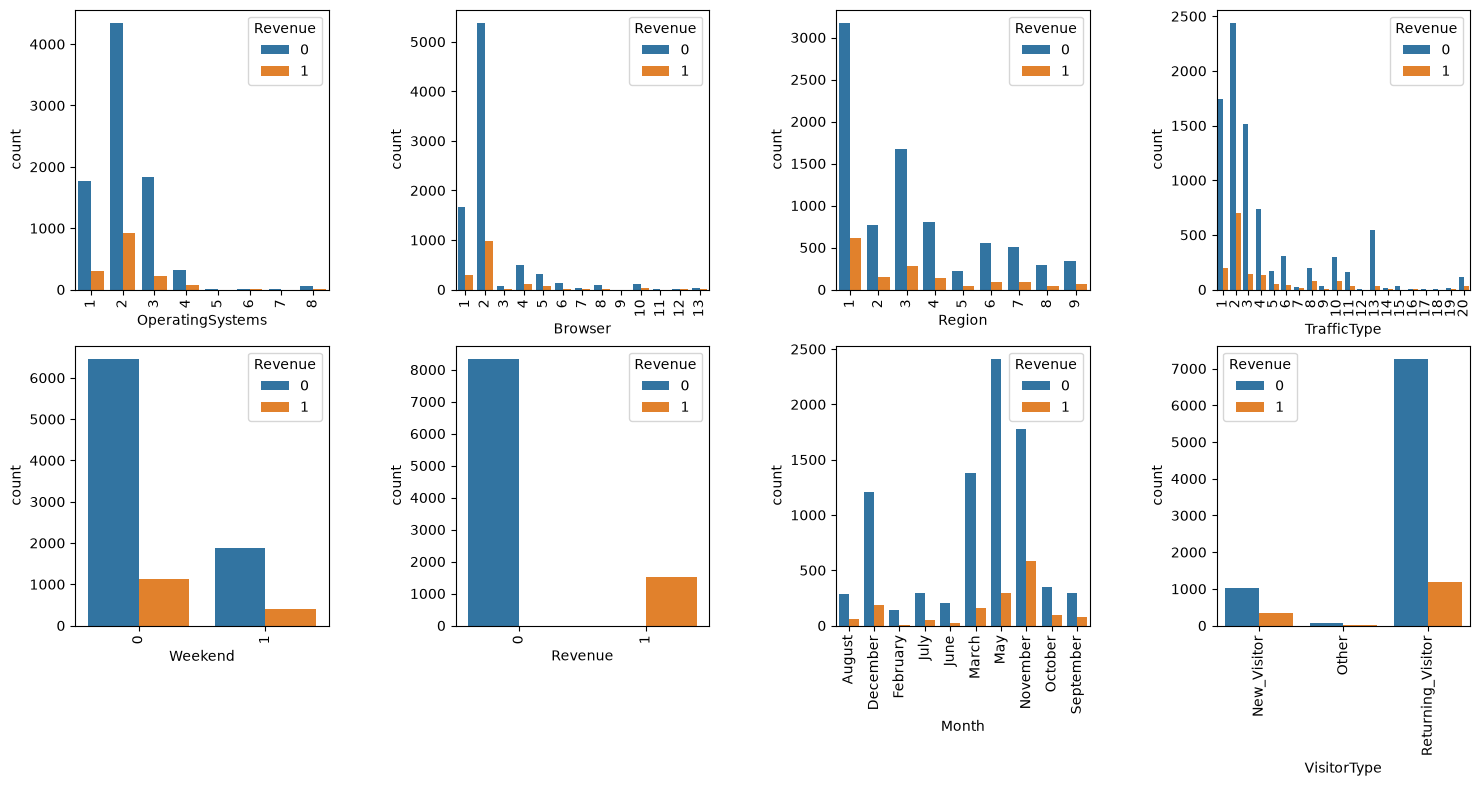

In [13]:
#1. Empieza el plot
fig_univ_cat_revenue, axes = plt.subplots(2, 4, figsize=(18,8))
axes = axes.flatten()

#2. Generamos boxplots = a plot_boxplot_custom para cada columna
for i, column in enumerate(cols_cat):
    #Generamos countplot
    sns.countplot(data=train_set, hue="Revenue",x=train_set[column].astype('category'), ax=axes[i])
#3. Para añadir espacio entre plots
plt.subplots_adjust(wspace=0.5)
for ax in fig_univ_cat_revenue.axes: ax.tick_params(axis='x', labelrotation=90)

Vemos que al representar esas variables categóricas separando por la variable target (`Revenue`), `Revenue`==0 se mantiene como el grupo mayoritario en la gran mayoría de categorías de las distintas variables. Aunque en ciertos casos la distancia relativa entre Revenues se acortan, la tendencia general de desbalanceo se conserva.

b) Hagamos un test de Asociación entre categóricas usando el test V Cramer:

Este test nos devuelve un rango de 0 a 1, donde 0 indica ausencia total de relación (variables independientes) y 1 indica asociación perfecta (conocer una variable predice exactamente la otra).

In [14]:
#Definimos una función para obtener la matriz de resultados
def matriz_cramerv(dataframe, cat_cols):
    #Definimos variables iniciales
    n=len(cat_cols)
    matriz_resultado = np.ones((n,n))
    #Para cada par operamos
    for i in range(n):
        for j in range(i+1, n):
            tmp_table = pd.crosstab(dataframe[cat_cols[i]],dataframe[cat_cols[j]])
            #Si tenemos más de una categoría en ambas calculamos
            if tmp_table.shape[0] > 1 and tmp_table.shape[1] > 1:
                tmp_v = association(tmp_table, method='cramer', correction=True)
            else:
                tmp_v = 0.0
            #Actualizamos valores en el array
            matriz_resultado[i,j] = tmp_v
            matriz_resultado[j,i] = tmp_v
    #Guardamos el resultado final en pandas df y lo devolvemos
    return pd.DataFrame(matriz_resultado, index=cat_cols, columns=cat_cols)

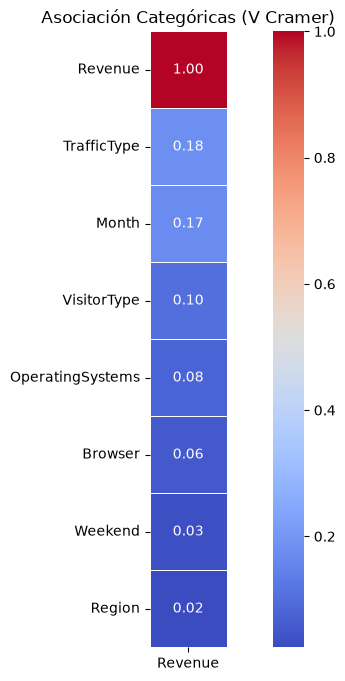

In [15]:
#Calculamos la matriz cramer V
#1. Obtenemos la matriz de correlación global y filtramos para Revenue
vcramer_matrix = matriz_cramerv(train_set, cols_cat)
vcramer_matrix_target = vcramer_matrix[["Revenue"]].sort_values(by='Revenue', ascending=False)
#Definimos tamaño
plt.figure(figsize=(12, 8))
#Generamos plot inicial
heat_target_vcramer = sns.heatmap(vcramer_matrix_target, annot=True, fmt=".2f", cmap="coolwarm", cbar=True, square=True, linewidths=.5)
#Añadimos titulo
heat_target_vcramer.set_title('Asociación Categóricas (V Cramer)')
#Mostrar plot
heat_target_vcramer;

Vemos algunas cosas:

- Vemos que las variables categóricas que presentan mayor asociación con la variable target están en un rango V Cramer 0.1-0.2, `TrafficType`, `Month` y `VisitorType`. Estas aportarían una señal de débil a moderada (0.1-0.3), así que serían interesantes de incorporar a los distintos modelos más adelante.

* Mientras que el resto de variables presentan una asociación muy débil en un rango entre 0.02-0.08. Así que podríamos plantearnos eliminarlas y no incorporarlas en los distintos modelos más adelante.

### 2.3.2. Variables numéricas

Ahora, vamos a hacer una correlación Spearman sobre datos train originales y correlación Pearson sobre datos train transformados. En este caso como el target es una variable binaria si que se puede usar un test de correlación de Pearson y Spearman, si fuera nominal de más de dos categorías no sería correcto.

a) Correlación Spearman sobre datos train originales:

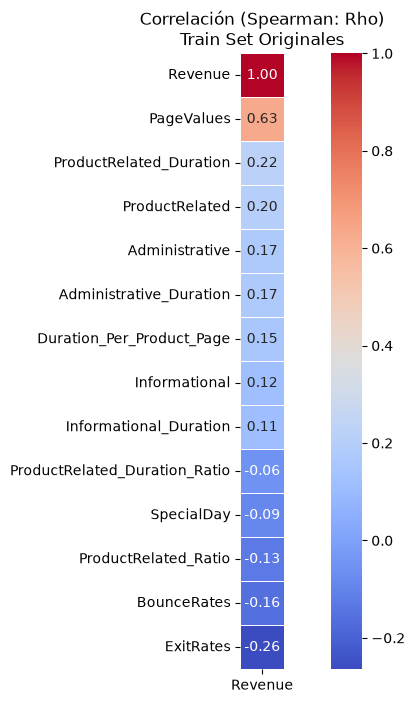

In [16]:
#Correlación Spearman sobre datos train originales
#0. Definimos columnas de interés
cols_4_corr = cols_num + ["Revenue"]
#1. Obtenemos la matriz de correlación global y filtramos para Revenue
corr_matrix_spearman = train_set[cols_4_corr].corr(numeric_only= True, method="spearman") # Si no lo pones y tienes variables tipo texto, fallará
corr_spearman_target = corr_matrix_spearman[["Revenue"]].sort_values(by='Revenue', ascending=False)
#Definimos tamaño
plt.figure(figsize=(12, 8))
#Generamos plot inicial
heat_target_spearman = sns.heatmap(corr_spearman_target, annot=True, fmt=".2f", cmap="coolwarm", cbar=True, square=True, linewidths=.5)
#Añadimos titulo
heat_target_spearman.set_title('Correlación (Spearman: Rho)\nTrain Set Originales')
#Mostrar plot
heat_target_spearman;

b) Correlación Pearson sobre datos train transformados:

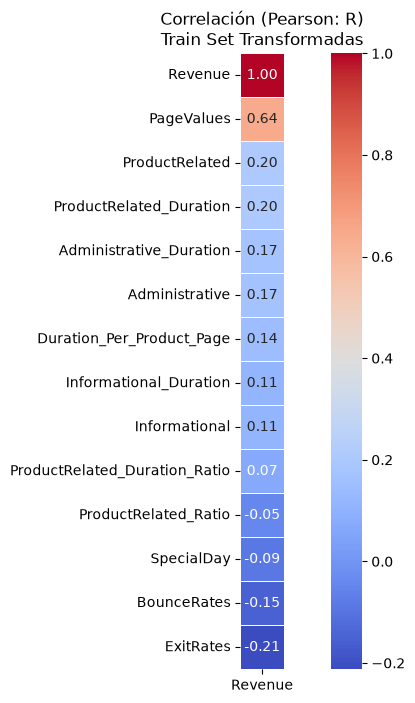

In [17]:
#Correlación Pearson sobre datos train transformados
#1. Obtenemos la matriz de correlación global y filtramos para Revenue
corr_matrix_pearson = train_set_nums_prep[cols_4_corr].corr(numeric_only= True, method="pearson") # Si no lo pones y tienes variables tipo texto, fallará
corr_pearson_target = corr_matrix_pearson[["Revenue"]].sort_values(by='Revenue', ascending=False)
#Definimos tamaño
plt.figure(figsize=(12, 8))
#Generamos plot inicial
heat_target_pearson = sns.heatmap(corr_pearson_target, annot=True, fmt=".2f", cmap="coolwarm", cbar=True, square=True, linewidths=.5)
#Añadimos titulo
heat_target_pearson.set_title('Correlación (Pearson: R)\nTrain Set Transformadas')
#Mostrar plot
heat_target_pearson;

Vemos algunas cosas:
- `PageValues` es la variable con mayor correlación con la variable target como ya predijimos (Pearson=0.64 y Spearman=0.63). Para nuestro objetivo, será conveniente eliminarla antes del modelado, ya que podría introducir un cierto *data leakage* y contaminar el *propensity score* que queremos generar más adelante. Esto no nos interesa, ya que nos gustaría que el modelo identificara usuarios que mostraron comportamientos similares a los compradores para futuras campañas de retargeting de los no compradores.
* `ProductRelated_Duration_Ratio` muestra una correlación muy baja con el target cercana a cero (aunque curiosamente cambia el signo, Pearson=0.07 y Spearman=-0.06). 
- Mientras que el resto de variables presentan correlaciones similares en ambos casos. Encontramos correlaciones positivas con el target, en rango 0.22-0.1(`ProductRelated`,`ProductRelated_Duration`, `Administrative`, `Administrative_Duration`, `Duration_Per_Product_Page`, `Informational`, `Informational_Duration`). También correlaciones negativas con el target en un rango -0.05 a -0.26 (`ProductRelated_Ratio` y `SpecialDay`, `BounceRates` y `ExitRates`), siendo `BounceRates` (Pearson=-0.15 y Spearman=-0.16) y `ExitRates` (Pearson=-0.21 y Spearman=-0.26) las que presenten mayor correlación negativa.

## 2.4. Multivariante entre features

### 2.4.1. Variables Categóricas

Vamos a hacer los análisis de correlación anteriores centrados en las variables categóricas:

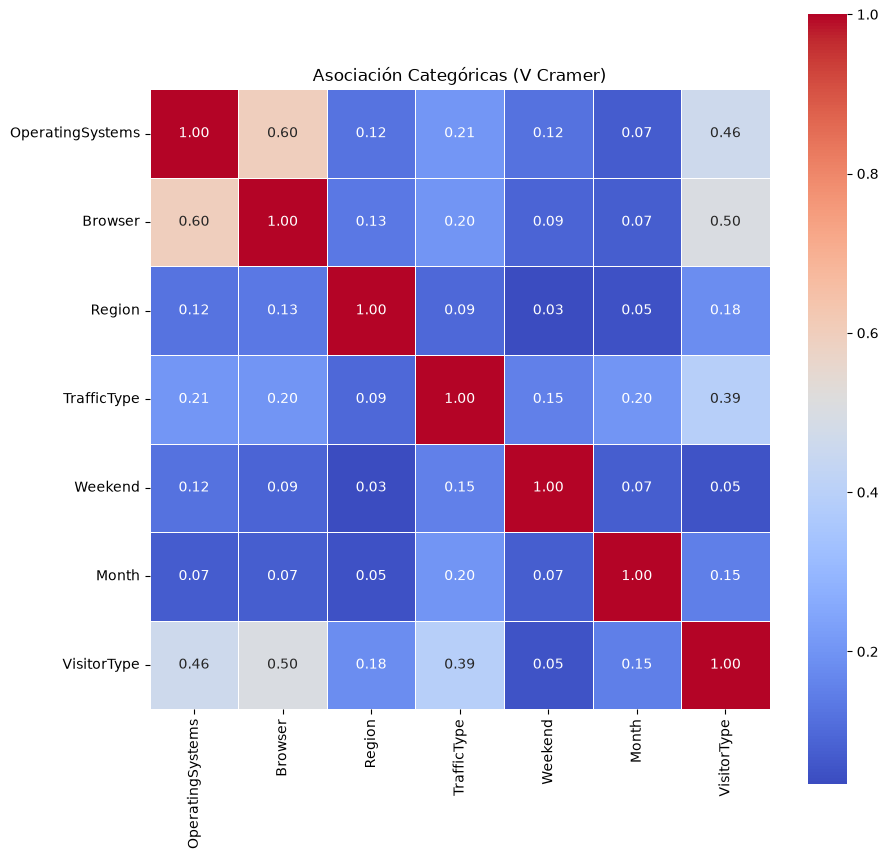

In [18]:
#Asociación V Cramer
#1. Usamos la matriz anterior y filtramos Revenue
vcramer_matrix_colnums =  vcramer_matrix.drop(index='Revenue', columns='Revenue')
#Definimos tamaño
plt.figure(figsize=(10, 10))
#Generamos plot inicial
heat_colcats_vcrames = sns.heatmap(vcramer_matrix_colnums, annot=True, fmt=".2f", cmap="coolwarm", cbar=True, square=True, linewidths=.5)
#Añadimos titulo
heat_colcats_vcrames.set_title('Asociación Categóricas (V Cramer)')
#Mostrar plot
heat_colcats_vcrames;

Vemos algunas cosas:

- Hay una colinealidad fuerte entre `OperatingSystems` y `Browser` (V = 0.6), así como asociaciones moderadas con `VisitorType` (V = 0.46 y V = 0.5, respectivamente) y débiles con `TrafficType` (V en torno a 0.2). También vemos que `TrafficType` tiene asociaciones débiles con `Weekend` (V = 0.15), y `VisitorType` con `Region` (V = 0.18). De manera que parte de esa información técnica, temporal y geográfica queda reflejada también en las tres variables categóricas de interés antes mencionadas (`VisitorType`, `TrafficType`, y `Month`).

* Las tres variables categóricas de interés muestran asociaciones débiles o moderadas entre sí (V entre 0.15 y 0.39), lo que indicaría que no son redundantes aportando información complementaria sin introducir problemas de multicolinealidad.

### 2.4.2. Variables Numéricas

Vamos a hacer los análisis de correlación anteriores centrados en las variables numéricas.

a) Correlación Spearman sobre datos train originales:

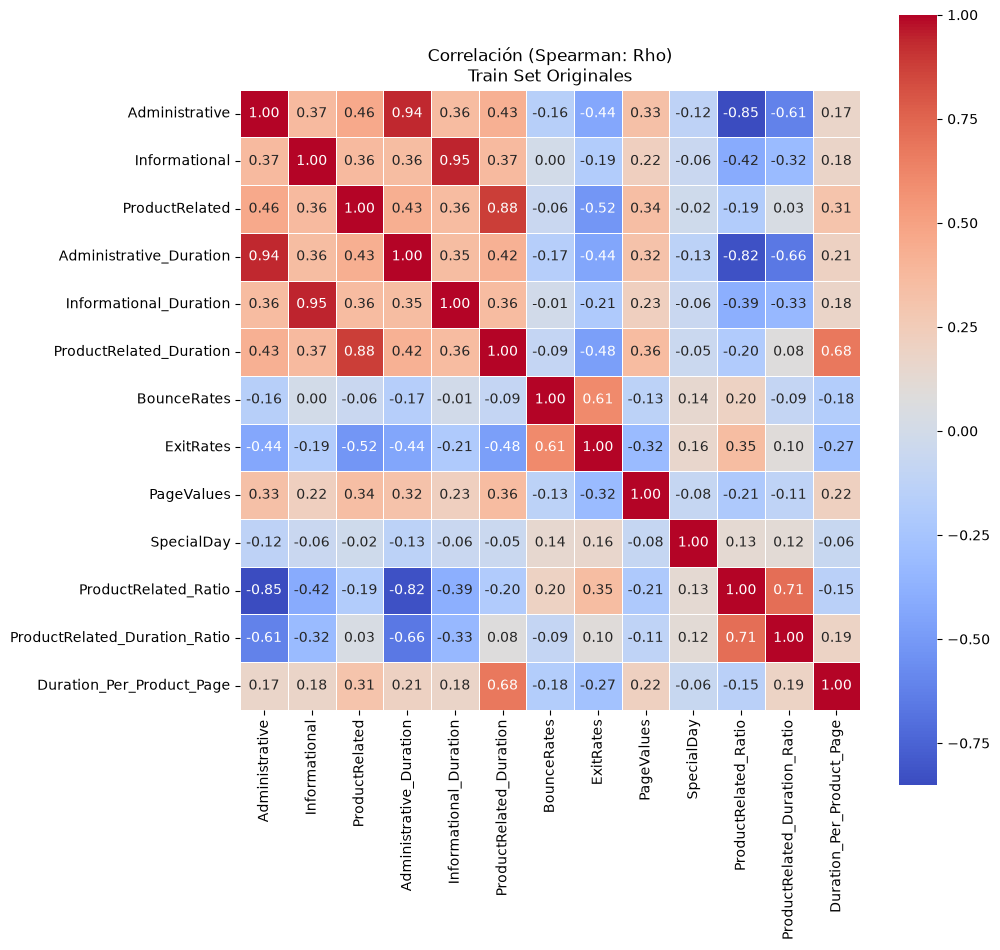

In [19]:
#Correlación Spearman sobre datos train originales
#1. Usamos la matriz anterior y filtramos Revenue
corr_matrix_spearman_colnums =  corr_matrix_spearman.drop(index='Revenue', columns='Revenue')
#Definimos tamaño
plt.figure(figsize=(10, 10))
#Generamos plot inicial
heat_colnums_spearman = sns.heatmap(corr_matrix_spearman_colnums, annot=True, fmt=".2f", cmap="coolwarm", cbar=True, square=True, linewidths=.5)
#Añadimos titulo
heat_colnums_spearman.set_title('Correlación (Spearman: Rho)\nTrain Set Originales')
#Mostrar plot
heat_colnums_spearman;

b) Correlación Pearson sobre datos train transformados:

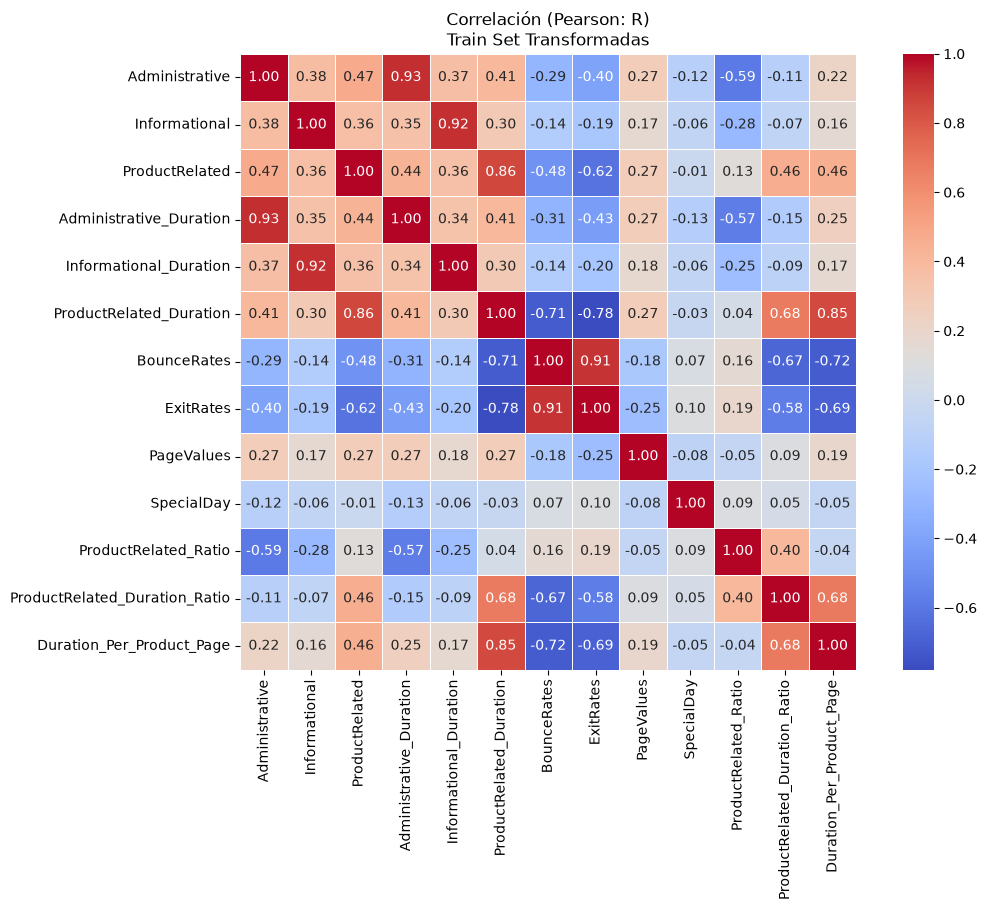

In [20]:
#Correlación Pearson sobre datos train transformados
#1. Usamos la matriz anterior y filtramos Revenue
corr_matrix_pearson_colnums =  corr_matrix_pearson.drop(index='Revenue', columns='Revenue')
#Definimos tamaño
plt.figure(figsize=(12, 8))
#Generamos plot inicial
heat_colnums_pearson = sns.heatmap(corr_matrix_pearson_colnums, annot=True, fmt=".2f", cmap="coolwarm", cbar=True, square=True, linewidths=.5)
#Añadimos titulo
heat_colnums_pearson.set_title('Correlación (Pearson: R)\nTrain Set Transformadas')
#Mostrar plot
heat_colnums_pearson;

Vemos algunas cosas:

- Vemos que la estructura general de correlaciones se mantiene antes y después de aplicar las transformaciones, aunque al aplicar estas transformaciones los valores de correlación aumentan en varios casos.

- Al comparar las variables referentes a las 3 categorías de páginas (`Administrative`,`Informational`, y `ProductRelated`) entre su número páginas y su respectiva duración hay una alta correlación (R = 0.86-0.93), como cabría esperar, pero al proporcionar dimensiones distintas, vamos a conservarlas.

* En el caso de `BounceRates` y `ExitRates`, están muy correlacionadas (R = 0.91) y ambas miden abandono, así que quizás sea recomendable eliminar `BounceRates` y quedarnos `ExitRates` que será más informativa.

- También vemos que la variable derivada `Duration_Per_Product_Page` muestra una correlación fuerte con `ProductRelated_Duration` (R = 0.85), como miden una dimensión temporal similar y por mantener una estructura homogénea con las otras variables `Administrative_Duration` y `Informational_Duration`, quizás sea recomendable eliminar `Duration_Per_Product_Page` y conservar `ProductRelated_Duration`.

* Finalmente, el resto de correlaciones serían moderadas o bajas (|R| menor 0.8), por lo que en principio no deberían ser problemáticas entre sí.

### 2.4.3. Variables categóricas vs numéricas

Ahora, vamos a usar el metodo kruskal y calcular el valor eta2, que podemos usar para cuantificar la fuerza de asociación (tamaño del efecto) entre una variable categórica y otra numérica, en un rango acotado entre 0-1.

In [21]:
#Definimos una función para obtener la matriz de resultados
def matriz_kruskal_wallis_with_eta2(dataframe, variables_categoricas, variables_numericas, alpha=0.05):
    """
    Genera una tabla resumen con los resultados del test de Kruskal-Wallis para todas las combinaciones posibles de variables categóricas y numéricas.
    Además, calcula el eta2 = (stat_h - k + 1) / (n - k), donde n= número de filas y k= número de categorías únicas.
    """
    # Iniciar lista resultados
    resultados = []

    # Iterar por cada par categórico-numérico
    for var_cat in variables_categoricas:
        for var_num in variables_numericas:
            #1. Preparamos datos
            # Filtramos nulos de ambas columnas para tener el 'n' exacto del par
            df_dropna = dataframe[[var_cat, var_num]].dropna()
            n = len(df_dropna)

            # Agrupamos por categoría
            grupos = [
                sub_df[var_num]
                for nombre, sub_df in df_dropna.groupby(var_cat)
            ]
            k = len(grupos)

            # 2. Calcular el test de Kruskal-Wallis y eta2
            if k > 1 and n > k:
                stat_h, p_valor = kruskal(*grupos)
                eta2 = max(0.0, (stat_h - k + 1) / (n - k)) #eta2 <0, se trunca siempre a 0.0
            else:
                stat_h, p_valor, eta2 = 0.0, 1.0, 0.0
            # 3. Determinar si hay diferencias significativas (alfa = 0.05)
            es_significativo = "Sí" if p_valor <= alpha else "No"

            # 4. Guardar los datos en un diccionario temporal
            resultados.append(
                    {
                        "Variable_Categorica": var_cat,
                        "Variable_Numerica": var_num,
                        "n":n, "k":k,
                        "Test": "Kruskal-Wallis",
                        "Estadistico_H": round(stat_h, 4),
                        "P_Valor": p_valor,
                        "Alpha": alpha,
                        "Significativo": es_significativo,
                        "Eta2": round(eta2, 4),
                    }
                )
    # 5. Convertir la lista de resultados en un DataFrame y devolver
    df_resultados = pd.DataFrame(resultados)
    return df_resultados

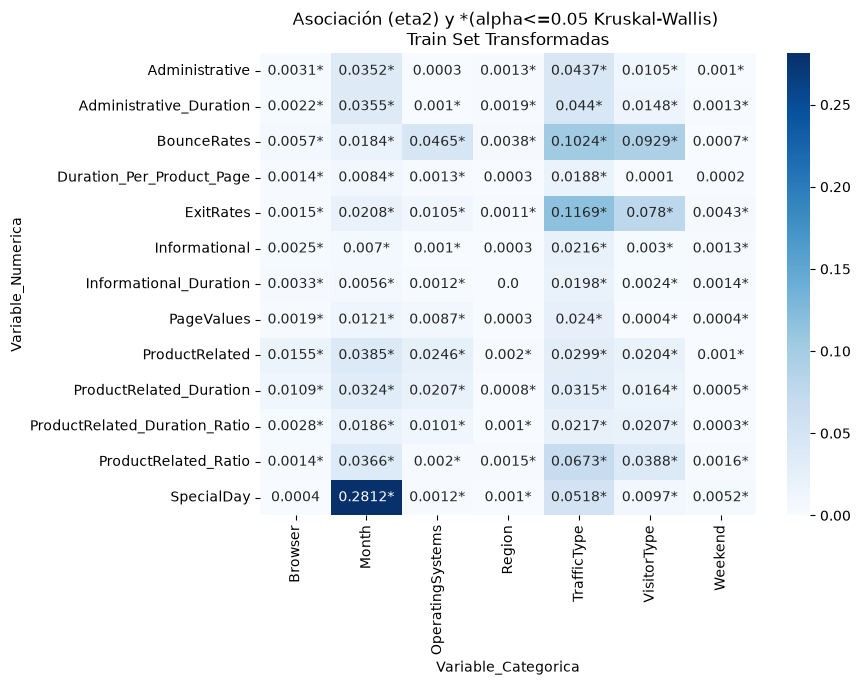

In [22]:
#Obtenemos la matriz le vamos forma para representar el eta2 y filtramos revenue
matriz_kruskal_eta2=matriz_kruskal_wallis_with_eta2(train_set_nums_prep, cols_cat, cols_num)
matriz_kruskal_eta2_without_target = matriz_kruskal_eta2[matriz_kruskal_eta2["Variable_Categorica"] != "Revenue"]
# 2. Transformar la tabla larga en matriz (Numéricas en filas, Categóricas en columnas)
matriz_eta2 = matriz_kruskal_eta2_without_target.pivot(index="Variable_Numerica", columns="Variable_Categorica", values="Eta2")

# (Opcional) Si quieres marcar con un asterisco '*' las que son significativas:
matriz_sig = matriz_kruskal_eta2_without_target.pivot(index="Variable_Numerica", columns="Variable_Categorica", values="Significativo")
etiquetas = matriz_eta2.astype(str) + np.where(matriz_sig == "Sí", "*", "")

# 3. Graficar el Heatmap
plt.figure(figsize=(8, 6))
heat_eta2 = sns.heatmap(matriz_eta2, annot=etiquetas,fmt="", cmap="Blues")
heat_eta2.set_title('Asociación (eta2) y *(alpha<=0.05 Kruskal-Wallis) \nTrain Set Transformadas')
heat_eta2;

Vemos que tenemos, basándonos en los cortes de las reglas de Cohen adaptadas:

- Algunas asociaciones fuertes (> 0.14), entre `Month` y `SpecialDay` (eta2 = 0.2812), lo cual tiene sentido ya que las fechas especiales están en meses concretos.

* También moderadas (0.06-0.14), en especial en `TrafficType` (`ProductRelated_Ratio` con eta2 = 0.0673, `ExitRates` con eta2 = 0.1169 y `BounceRates` con eta2 = 0.1024) y `VisitorType` (`ExitRates` con eta2 = 0.078 y `BounceRates` con eta2 = 0.0929). Lo que indicaría que el patrón de navegación y abandono varía según el canal y el tipo de usuario.

- Mientras que el resto presentan asociaciones pequeñas (0.01-0.06) o nulas (< 0.01), indicando que aportan información mayoritariamente complementaria sin redundancia importante.


## 2.5. Selección de variables
En base a los resultados de este EDA, se ha decidido no incluir las siguientes variables en los modelos más adelante:

- Las variables `Region`, `Weekend`, `Browser`, y `OperatingSystems` presentan una asociación muy débil con la variable target en un rango V Cramer 0.02-0.08, así que no las incluiremos en los modelos para reducir ruido y dimensionalidad.

* `PageValues` es la variable con mayor correlación con la variable target. Para nuestro objetivo, será conveniente eliminarla antes del modelado, ya que podría introducir un cierto *data leakage* y contaminar el *propensity score* que queremos generar más adelante. Esto no nos interesa, ya que nos gustaría que el modelo identificara usuarios que mostraron comportamientos similares a los compradores para futuras campañas de retargeting de los no compradores.

- En el caso de `BounceRates` y `ExitRates`, están muy correlacionadas (R = 0.91) y ambas miden abandono, así que vamos a eliminar `BounceRates` y quedarnos `ExitRates` que será más informativa.

* También vemos que la variable derivada `Duration_Per_Product_Page` muestra una correlación fuerte con `ProductRelated_Duration` (R = 0.85), como miden una dimensión temporal similar y por mantener una estructura homogénea con las otras variables, vamos a eliminar `Duration_Per_Product_Page` y conservar `ProductRelated_Duration`.

De manera que nuestras variables finales serán:

- **Target**: `Revenue` (Binaria, Categórica).

* **Features**:
    - Categóricas: `Month`, `VisitorType` y `TrafficType`.
    * Numéricas: `ProductRelated`,`ProductRelated_Duration`, `Administrative`, `Administrative_Duration`, `Informational`, `Informational_Duration`, `ProductRelated_Ratio`, `ProductRelated_Duration_Ratio`, `SpecialDay` y `ExitRates`.

**Nota:** Esto lo tendremos en cuenta a la hora de preparar el `src/data_processing.py`.


## 2.6. Comentarios sobre variables categóricas de interés
Por otro lado, también debemos pensar en como tratar las variables categóricas seleccionadas más adelante:

- `Month`: el dataset entero tenía solo 10 de 12 meses posibles (faltando enero y abril), y en el train los 10 meses están representados. Así que la opción más sencilla para esta variable es `OneHotEncoder` con un `handle_unknown='ignore'` para que así en un futuro datos nulos (NaN) y los dos meses del año faltantes en el dataset, aparezcan con ceros en todas las columnas Month asociadas. Esto también es una limitación a tener en cuenta, pues nuestros modelos no tendrán información sobre los meses de enero y abril.

* `VisitorType`: el dataset entero tenía 3 tipos de visitantes, que han quedado representados en el train. Así que la opción más sencilla para esta variable es también un `OneHotEncoder` con un `handle_unknown='ignore'`.

- `TrafficType`: el dataset entero tenía 20 tipos de tráfico, que han quedado reflejados en el train set. La opción más cómoda será otra vez un `OneHotEncoder` con un `handle_unknown='ignore'` y `min_frequency=0.01`. Esto agrupará los canales conocidos que son poco frecuentes (< 1%) en una columna TrafficType_infrequent_sklearn. Además, para que los NaN no fastidien el OneHotEncoder para esta variable que está codificada como int, quizás sería interesante transformarla a str antes de pasarla por el OneHotEncoder.